# Program 7 — Pedestrian Detection System

**Aim:** Implement and evaluate a Pedestrian Detection System using OpenCV and the
Histogram of Oriented Gradients (HOG) descriptor.

**Method:** OpenCV's `HOGDescriptor` with the built-in linear SVM people detector
is run at multiple scales; detections above a score threshold are drawn.

In [1]:
import cv2

import matplotlib.pyplot as plt


def show(img, title):
    """Display a BGR or grayscale OpenCV image inside the notebook."""
    plt.figure(figsize=(12, 7))
    if img.ndim == 2:
        plt.imshow(img, cmap="gray")
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


Working size: (480, 640, 3)


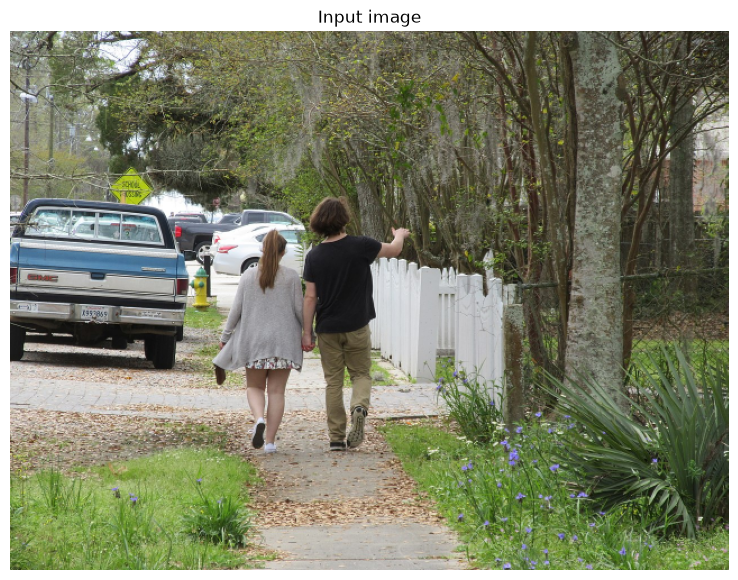

In [2]:
image = cv2.imread("pedestrians.jpg")
if image is None:
    raise FileNotFoundError("pedestrians.jpg not found")

# Resize so the detector runs at a sensible scale
image = cv2.resize(image, (640, int(640 * image.shape[0] / image.shape[1])))
output = image.copy()

print("Working size:", image.shape)
show(image, "Input image")

In [3]:
hog = cv2.HOGDescriptor()
hog.setSVMDetector(cv2.HOGDescriptor_getDefaultPeopleDetector())

boxes, weights = hog.detectMultiScale(image, winStride=(4, 4),
                                      padding=(8, 8), scale=1.03)

for box, score in zip(boxes, weights):
    print("box", tuple(int(v) for v in box), " score", round(float(score), 2))

box (220, 118, 150, 301)  score 2.13
box (169, 158, 128, 256)  score 0.29


In [4]:
min_score = 0.25
count = 0

for (x, y, w, h), score in zip(boxes, weights):

    if score < min_score:
        continue

    count += 1
    cv2.rectangle(output, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(output, f"Person {float(score):.2f}", (x, max(y - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 2)

print("Pedestrians detected:", count)

Pedestrians detected: 2


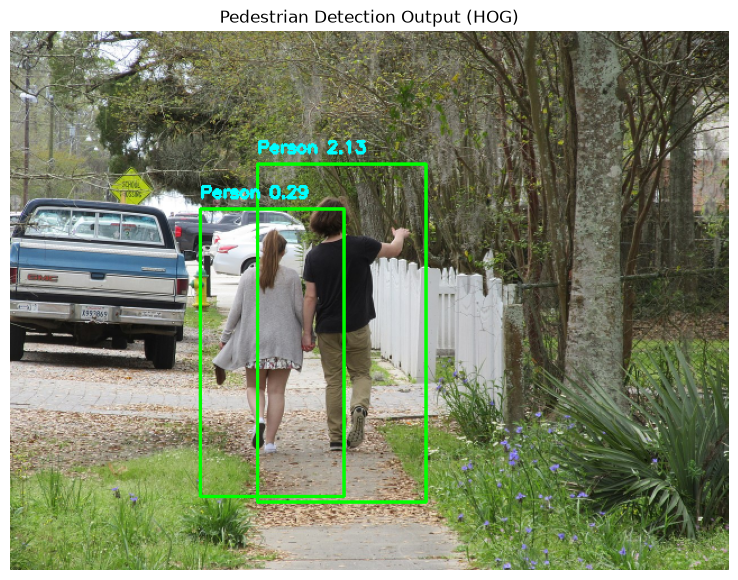

In [5]:
cv2.imwrite("output.jpg", output)
show(output, "Pedestrian Detection Output (HOG)")